In [131]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree 
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
ConfusionMatrixDisplay, roc_curve)

In [132]:
# Set up visuals

sns.set(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 5),
                     "axes.labelsize": 12,
                     "axes.titlesize": 14})

In [133]:
# Load Dataset

df = pd.read_csv("adult-depression-lghc-indicator-24.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (161, 8)


,Year,Strata,Strata Name,Frequency,Weighted Frequency,Percent,Lower 95% CL,Upper 95% CL
0,2012,Total,Total,1920,NaN,11.74,11.11,12.37
1,2012,Sex,Male,561,1116664.0,8.12,7.32,8.92
2,2012,Sex,Female,1359,2163108.0,15.25,14.30,16.20
3,2012,Race-Ethnicity,White,1314,1806371.0,14.57,13.67,15.46
4,2012,Race-Ethnicity,Black,97,222022.0,13.54,10.44,16.65


## Exploratory Data Analysis (EDA)

In [134]:
# Check for missing values

print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Year                  0
Strata                0
Strata Name           0
Frequency             0
Weighted Frequency    7
Percent               0
Lower 95% CL          0
Upper 95% CL          0
dtype: int64


In [135]:
# Summary statistics

df.describe(include="all")

,Year,Strata,Strata Name,Frequency,Weighted Frequency,Percent,Lower 95% CL,Upper 95% CL
count,161.00000,161,161,161.000000,1.540000e+02,161.000000,161.000000,161.000000
unique,NaN,6,23,NaN,NaN,NaN,NaN,NaN
top,NaN,Income,Total,NaN,NaN,NaN,NaN,NaN
freq,NaN,42,7,NaN,NaN,NaN,NaN,NaN
mean,2015.00000,NaN,NaN,429.776398,8.898917e+05,14.789627,11.955280,17.624224
std,2.00624,NaN,NaN,390.297867,6.299145e+05,4.589876,3.705456,5.890040
min,2012.00000,NaN,NaN,28.000000,9.230900e+04,3.970000,2.000000,5.340000
25%,2013.00000,NaN,NaN,186.000000,4.597088e+05,11.850000,9.650000,13.870000
50%,2015.00000,NaN,NaN,314.000000,7.164805e+05,14.520000,11.550000,16.930000
75%,2017.00000,NaN,NaN,511.000000,1.109084e+06,17.190000,14.600000,20.050000


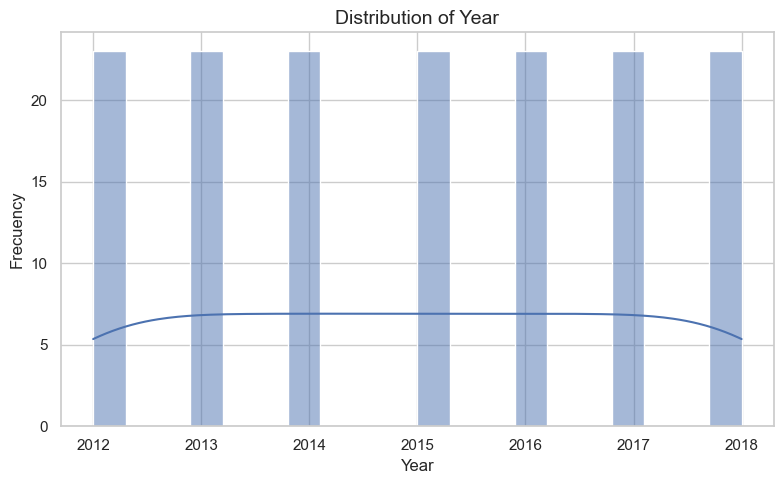

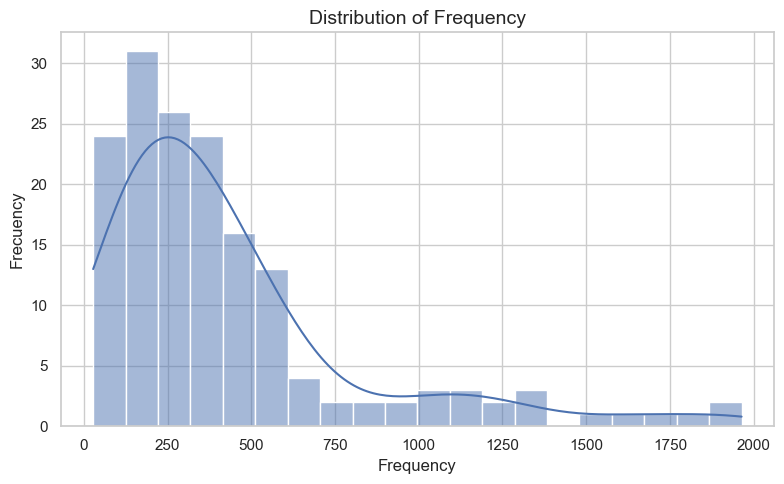

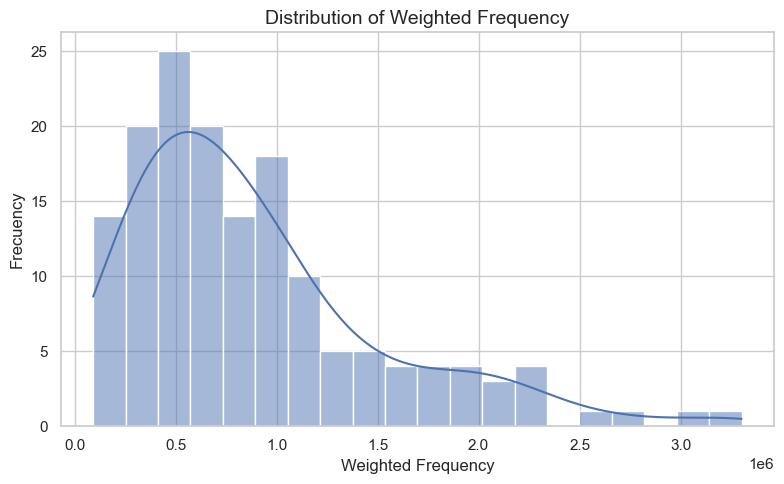

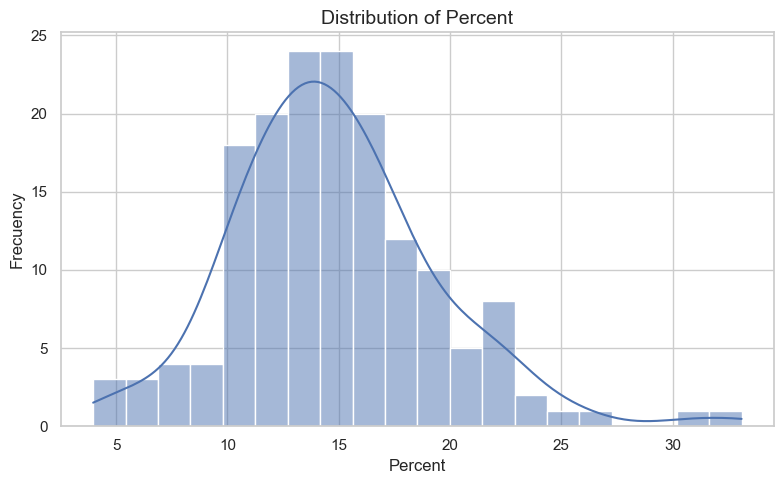

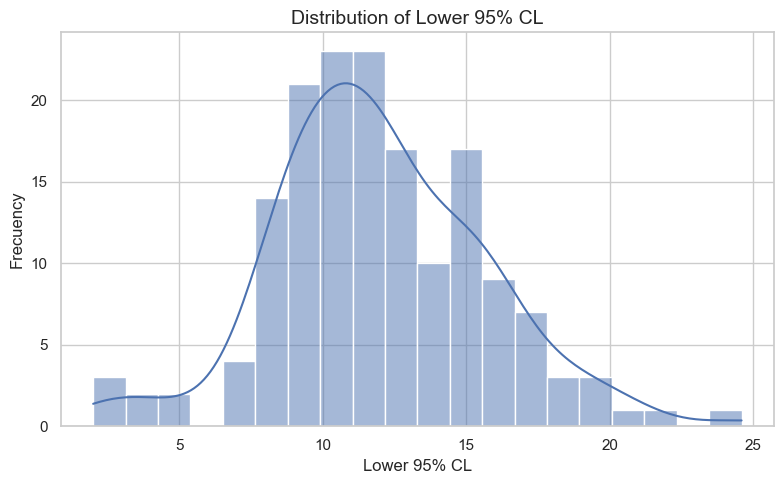

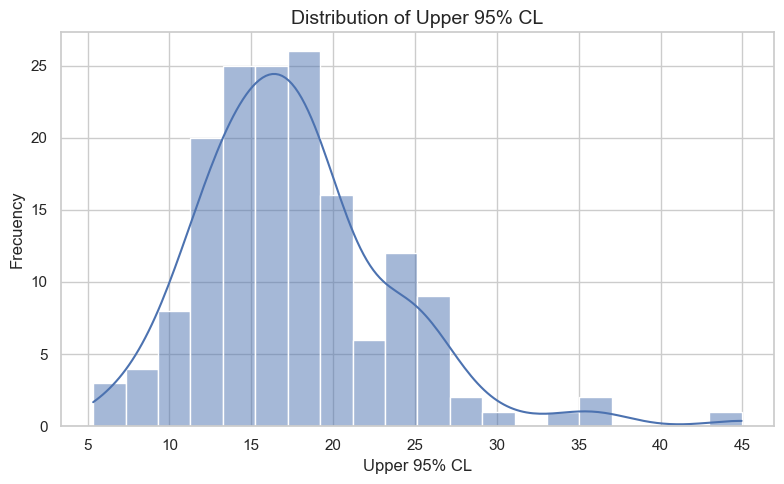

In [136]:
# Histograms for numeric columns

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure()
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuency")
    plt.tight_layout()
    plt.show()

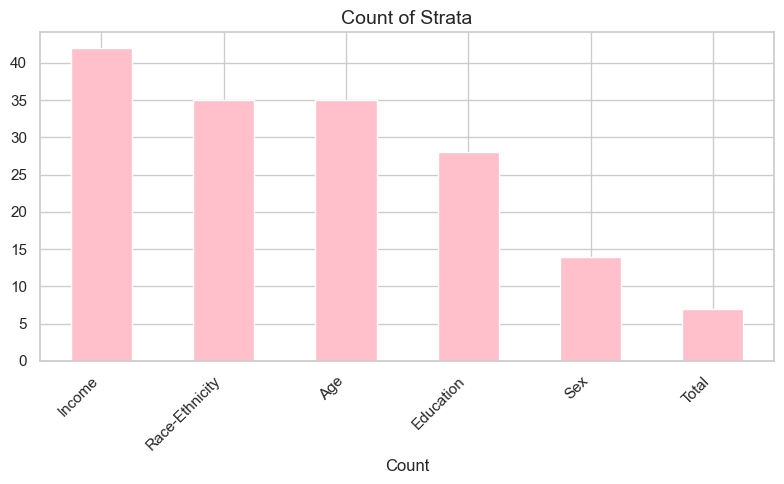

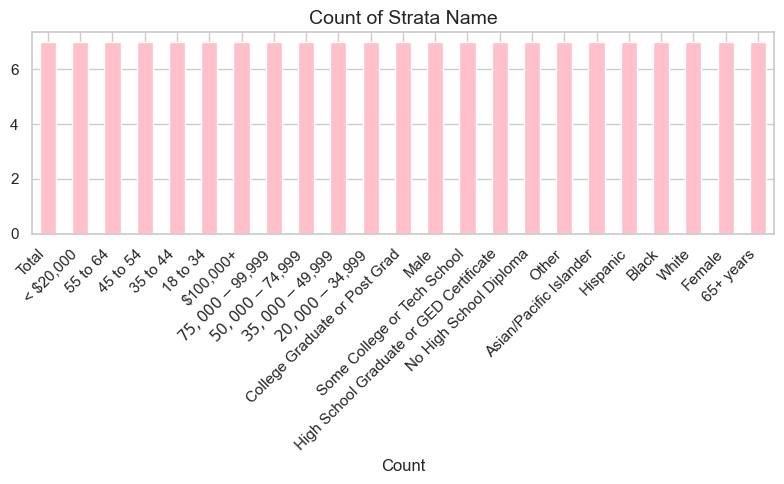

In [137]:
# Bar charts for categorical columns

cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    plt.figure()
    df[col].value_counts().plot(kind="bar", color="pink")
    plt.title(f"Count of {col}")
    plt.xlabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

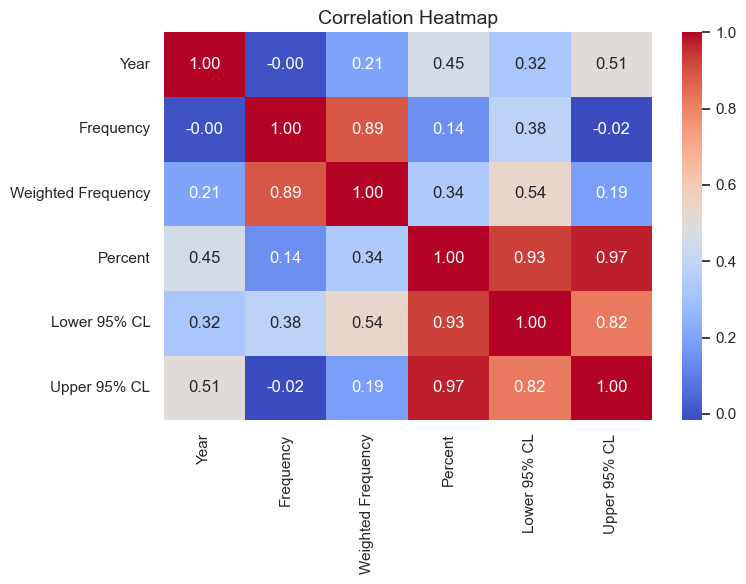

In [138]:
# Correlation matrix

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Create Target Variable

In [139]:
# Create a binary target column: HighDepression

median_threshold = df["Percent"].median()
df["HighDepression"] = (df["Percent"] > median_threshold).astype(int)

print(f"Median Percent: {median_threshold:.3f}")
df["HighDepression"].value_counts()

Median Percent: 14.520


HighDepression
0    81
1    80
Name: count, dtype: int64

# Prepare Data for Modeling

In [140]:
# Define features and target

X = df.drop(columns=["HighDepression", "Percent"])
y = df["HighDepression"]

# Separate numeric and catagorical columns

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()

# Preprocessing pipeline

preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), num_cols),
                                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

# Split data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Model Training--Logistic Regression & Decition Tree

In [141]:
# Numeric preprocessing: impute + scale

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),
                                      ("scaler", StandardScaler())])

# Categorical preprocessing: impute +one-hot encode

categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                         ("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing

preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, num_cols),
                                               ("cat", categorical_transformer, cat_cols)])

# Split data


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define models

models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42)}

# Train all models in a loop

fitted_models = {}

for name, clf in models.items():
    pipe = Pipeline([("preprocessor", preprocessor),
                     ("classifier", clf)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    print(f"✔️ {name} trained successfully")

✔️ Logistic Regression trained successfully
✔️ Decision Tree trained successfully


# Model Evaluation

==Logistic Regression==
Accuracy:  0.939
Precision: 0.889
Recall:    1.000
F1-Score:  0.941
ROC-AUC:   0.996



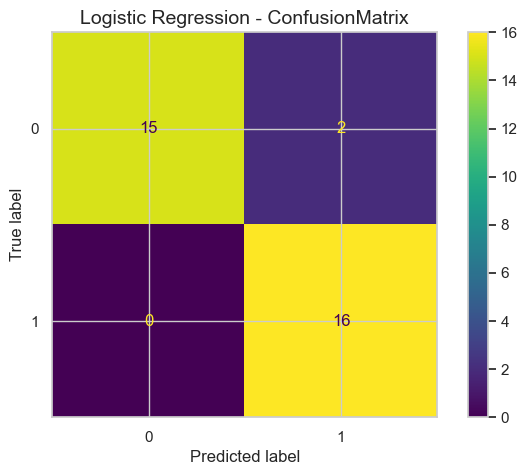

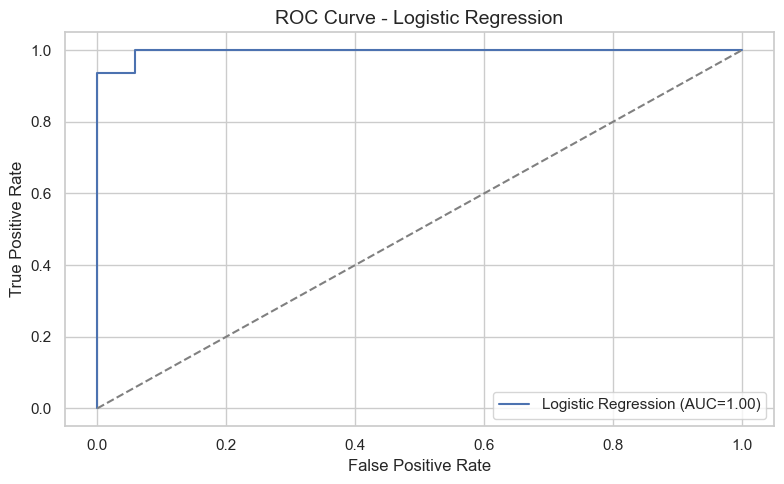

==Decision Tree==
Accuracy:  0.879
Precision: 0.833
Recall:    0.938
F1-Score:  0.882
ROC-AUC:   0.881



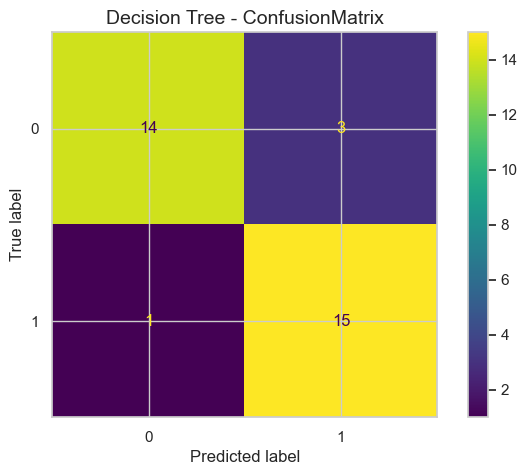

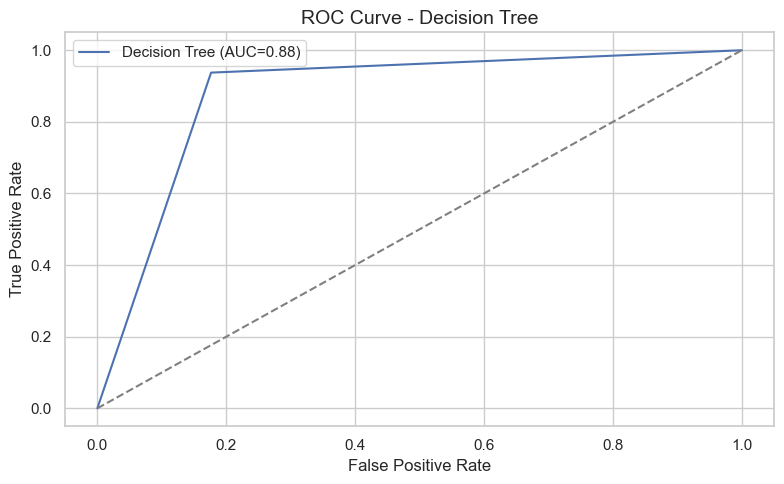

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.939394,0.888889,1.0000,0.941176,0.996324
1,Decision Tree,0.878788,0.833333,0.9375,0.882353,0.880515


In [142]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)


    print(f"=={name}==")
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}")
    print(f"F1-Score:  {f1:.3f}")
    print(f"ROC-AUC:   {roc:.3f}\n")


    # Confusion matrix

    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(f"{name} - ConfusionMatrix")
    plt.show()

    # ROC curve

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc:.2f})")
    plt.plot([0, 1], [0, 1], "--", color="grey")
    plt.title(f"ROC Curve - {name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()


    return{"Model": name,
           "Accuracy": acc,
           "Precision": prec,
           "Recall": rec,
           "F1": f1,
           "ROC-AUC": roc}

# Evaluate both models

results = []
for name, model in fitted_models.items():
    metrics = evaluate_model(model, X_test, y_test, name)
    results.append(metrics)

pd.DataFrame(results)

# Visualise the Decision Tree

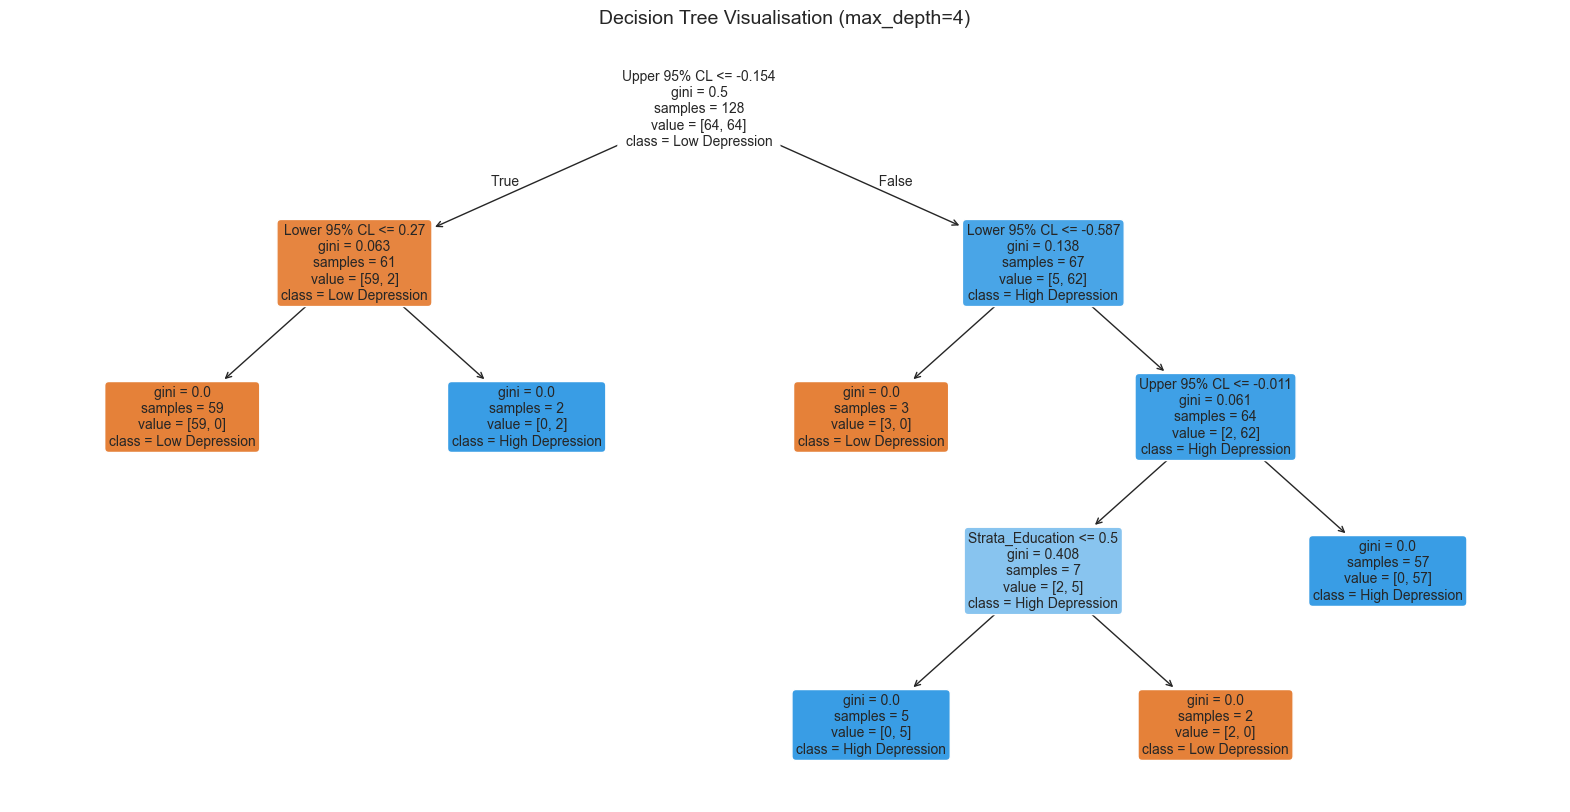

In [143]:
# Extract the decision tree pipeline

dt_pipeline = fitted_models["Decision Tree"]

# Extract the trained decisiontreeclassifier

dt_model = dt_pipeline.named_steps["classifier"]

# Extract feature names after one-hot encoder
# numeric + encoded categorical

ohe = dt_pipeline.named_steps["preprocessor"].transformers_[1][1]
cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + cat_feature_names

# Plot the tree

plt.figure(figsize=(20, 10))
plot_tree(dt_model,
          filled=True,
          feature_names=feature_names,
          class_names=["Low Depression", "High Depression"],
          rounded=True,
          fontsize=10)
plt.title("Decision Tree Visualisation (max_depth=4)")
plt.show()         